# 딥러닝응용프로그래밍 — 2주차 실습
## Tensor와 PyTorch 기초

## 0. 환경 확인

In [13]:
import torch

print('PyTorch version:', torch.__version__)
print('CUDA available:', torch.cuda.is_available())


PyTorch version: 2.14.0
CUDA available: False


# 실습 1. Scalar → Vector → Matrix → Tensor

In [2]:
s = torch.tensor(25)
v = torch.tensor([90,85,70])
m = torch.tensor([[90,85,70],[60,75,88]])
t = torch.tensor([[[1,2],[3,4]],[[5,6],[7,8]]])

for name,x in [('scalar',s),('vector',v),('matrix',m),('tensor3d',t)]:
    print(name, 'dim=', x.dim(), 'shape=', tuple(x.shape), 'numel=', x.numel())


scalar dim= 0 shape= () numel= 1
vector dim= 1 shape= (3,) numel= 3
matrix dim= 2 shape= (2, 3) numel= 6
tensor3d dim= 3 shape= (2, 2, 2) numel= 8


예제
1. 숫자 5개 Vector를 만들기
2. `(2,3,4)` Tensor 만들기
3. `numel()`로 전체 원소 수 확인
4. `(32,3,224,224)`가 어떤 데이터인지 설명

In [3]:
x = torch.tensor([10, 20, 30, 40, 50])
print("1. Vector : ",x)

y = torch.tensor([[[1,2,3,4], [5,6,7,8], [9,10,11,12]],[[13,14,15,16],[17,18,19,20],[21,22,23,24]]])
print("2. Tensor Shape : ", tuple(y.shape),"\n")

print("3. 전체 원소 수: ", y.numel(),"\n")

print("4. 설명\n224 x 224 크기의 컬러 (RGB) 이미지 32장으로 이루어진 Batch")

1. Vector :  tensor([10, 20, 30, 40, 50])
2. Tensor Shape :  (2, 3, 4) 

3. 전체 원소 수:  24 

4. 설명
224 x 224 크기의 컬러 (RGB) 이미지 32장으로 이루어진 Batch


# 실습 2. shape 읽기

In [4]:
x = torch.zeros(32,3,224,224)
print('shape:', x.shape)
print('dim:', x.dim())
print('numel:', x.numel())


shape: torch.Size([32, 3, 224, 224])
dim: 4
numel: 4816896


### 예제
`(32,3,224,224)`에서 각 숫자가 무엇을 의미하는지 설명하세요.

In [5]:
print("(32,3,224,224)에서 각 숫자의 의미 -> 32장의 이미지, 3(RGB)로 이루어짐, 224*224 크기의 이미지")

(32,3,224,224)에서 각 숫자의 의미 -> 32장의 이미지, 3(RGB)로 이루어짐, 224*224 크기의 이미지


### TODO: 아래에 한 줄 설명을 작성하세요.


# 실습 3. Indexing / Slicing
성적표 `shape=(30,3)`을 사용합니다.

In [6]:
torch.manual_seed(0)
scores = torch.randint(50,101,(30,3))
print(scores.shape)
print(scores[:5])


torch.Size([30, 3])
tensor([[ 91,  53,  79],
        [ 83,  69,  50],
        [ 66,  60,  90],
        [ 89, 100,  94],
        [ 80,  59,  75]])


In [7]:
print('1번 학생:', scores[0])
print('전체 학생 첫 과목:', scores[:,0])
print('1번 학생 두 번째 과목:', scores[0,1])
print('마지막 학생:', scores[-1])


1번 학생: tensor([91, 53, 79])
전체 학생 첫 과목: tensor([ 91,  83,  66,  89,  80,  91, 100,  94,  76,  58,  84,  83,  66,  51,
         72,  73,  97,  97,  76,  93,  87,  77,  78,  63,  92,  85,  54,  52,
         77,  69])
1번 학생 두 번째 과목: tensor(53)
마지막 학생: tensor([69, 81, 61])


### 예제
1. 10~20번째 학생의 첫 번째 과목
2. 전체 학생의 세 번째 과목
3. 앞 10명의 두 번째 과목
4. 마지막 3명의 전체 점수

In [8]:
print('1. 10~20번째 학생의 첫 번째 과목',scores[9:20,0])
print('\n2. 전체 학생의 세 번째 과목', scores[:,2])
print('\n3. 앞 10명의 두 번째 과목',scores[:10,1])
print('\n4. 마지막 3명의 전체 점수',scores[-3:])

1. 10~20번째 학생의 첫 번째 과목 tensor([58, 84, 83, 66, 51, 72, 73, 97, 97, 76, 93])

2. 전체 학생의 세 번째 과목 tensor([ 79,  50,  90,  94,  75,  56,  67,  55,  57,  98,  70,  71, 100,  71,
         66,  75,  63,  81,  73,  97,  89,  52,  85,  70,  74,  96,  58,  57,
         69,  61])

3. 앞 10명의 두 번째 과목 tensor([ 53,  69,  60, 100,  59,  53,  95,  82,  52,  95])

4. 마지막 3명의 전체 점수 tensor([[52, 79, 57],
        [77, 64, 69],
        [69, 81, 61]])


# 실습 4. dtype

In [9]:
print('현재 dtype:', scores.dtype)
scores_f = scores.float()
print('변환 후:', scores_f.dtype)
print('평균:', scores_f.mean())


현재 dtype: torch.int64
변환 후: torch.float32
평균: tensor(74.9444)


# 실습 5. device

In [10]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
x = scores_f.to(device)
print('device:', device)
print('tensor device:', x.device)


device: cpu
tensor device: cpu


# 실습 6. reshape

In [11]:
x = torch.arange(12)
print(x.reshape(3,4))
print(x.reshape(2,6))
print(x.reshape(2,-1))


tensor([[ 0,  1,  2,  3],
        [ 4,  5,  6,  7],
        [ 8,  9, 10, 11]])
tensor([[ 0,  1,  2,  3,  4,  5],
        [ 6,  7,  8,  9, 10, 11]])
tensor([[ 0,  1,  2,  3,  4,  5],
        [ 6,  7,  8,  9, 10, 11]])


### 직접 예측
`(24,)`을 `(2,12)`, `(3,8)`, `(4,6)`, `(5,5)`로 바꿀 수 있는지 먼저 적어보세요.

In [12]:
x = torch.arange(24)

print(x.reshape(2,12)) #가능
print(x.reshape(3,8)) #가능
print(x.reshape(4,6)) #가능
print(x.reshape(5,5)) #불가능

tensor([[ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11],
        [12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23]])
tensor([[ 0,  1,  2,  3,  4,  5,  6,  7],
        [ 8,  9, 10, 11, 12, 13, 14, 15],
        [16, 17, 18, 19, 20, 21, 22, 23]])
tensor([[ 0,  1,  2,  3,  4,  5],
        [ 6,  7,  8,  9, 10, 11],
        [12, 13, 14, 15, 16, 17],
        [18, 19, 20, 21, 22, 23]])


RuntimeError: shape '[5, 5]' is invalid for input of size 24

# 실습 7. `*`와 `@`

In [ ]:
a = torch.tensor([[1.,2.],[3.,4.]])
b = torch.tensor([[10.,20.],[30.,40.]])

print('a * b =\n', a*b)
print('a @ b =\n', a@b)


a * b =
 tensor([[ 10.,  40.],
        [ 90., 160.]])
a @ b =
 tensor([[ 70., 100.],
        [150., 220.]])


# 실습 8. `dim=`과 Broadcasting

In [ ]:
scores = scores.float()
bonus = torch.tensor([5.,0.,10.])

print('과목별 평균:', scores.mean(dim=0))
print('학생별 평균 shape:', scores.mean(dim=1).shape)
print('전체 +5 shape:', (scores+5).shape)
print('과목별 bonus shape:', (scores+bonus).shape)


과목별 평균: tensor([78.4667, 73.0667, 73.3000])
학생별 평균 shape: torch.Size([30])
전체 +5 shape: torch.Size([30, 3])
과목별 bonus shape: torch.Size([30, 3])


# 응용 실습. 이미지 한 장을 Tensor로 만들기

이미지의 shape을 다음 순서로 변화시킵니다.

`(H,W,C) → (C,H,W) → (Batch,C,H,W)`

zsh:1: command not found: apt-get
원본 이미지 크기: (976, 1227)


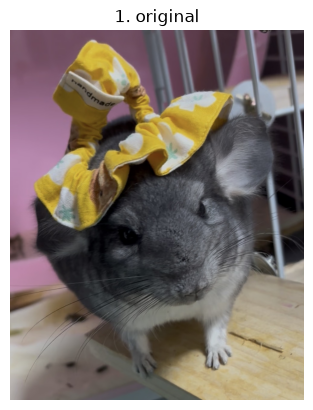

Resize 후: (224, 224)


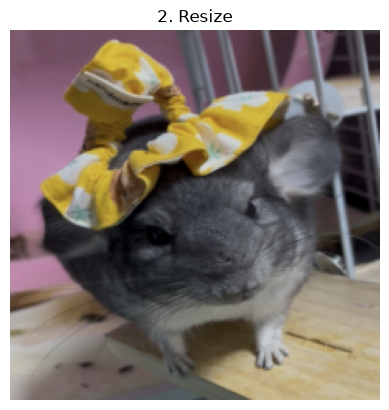

Tensor shape: torch.Size([3, 224, 224])
Tensor 최소값: tensor(0.)
Tensor 최대값: tensor(0.8510)


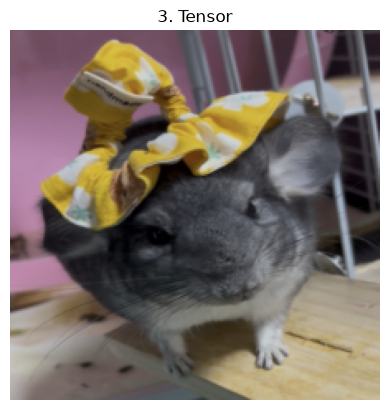

Batch shape: torch.Size([1, 3, 224, 224])


In [ ]:
!apt-get -qq install fonts-nanum

from PIL import Image
from torchvision import transforms
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm


# 1. 실제 이미지 불러오기
img = Image.open("sera.jpg").convert("RGB")

print("원본 이미지 크기:", img.size)

plt.imshow(img)
plt.title("1. original")
plt.axis("off")
plt.show()


# 2. Resize
resize = transforms.Resize((224, 224))
img_resize = resize(img)

print("Resize 후:", img_resize.size)

plt.imshow(img_resize)
plt.title("2. Resize")
plt.axis("off")
plt.show()


# 3. Tensor 변환
to_tensor = transforms.ToTensor()
img_t = to_tensor(img_resize)

print("Tensor shape:", img_t.shape)
print("Tensor 최소값:", img_t.min())
print("Tensor 최대값:", img_t.max())

plt.imshow(img_t.permute(1, 2, 0))
plt.title("3. Tensor",)
plt.axis("off")
plt.show()


# 4. Batch 차원 추가
batch = img_t.unsqueeze(0)

print("Batch shape:", batch.shape)

In [ ]:
# 현재 img_t = [3, 224, 224] 라고 가정

# 이미지 1장을 32장으로 복제
batch_32 = img_t.unsqueeze(0).repeat(32, 1, 1, 1)

print("이미지 1장:", img_t.shape)
print("Batch 32장:", batch_32.shape)

이미지 1장: torch.Size([3, 224, 224])
Batch 32장: torch.Size([32, 3, 224, 224])


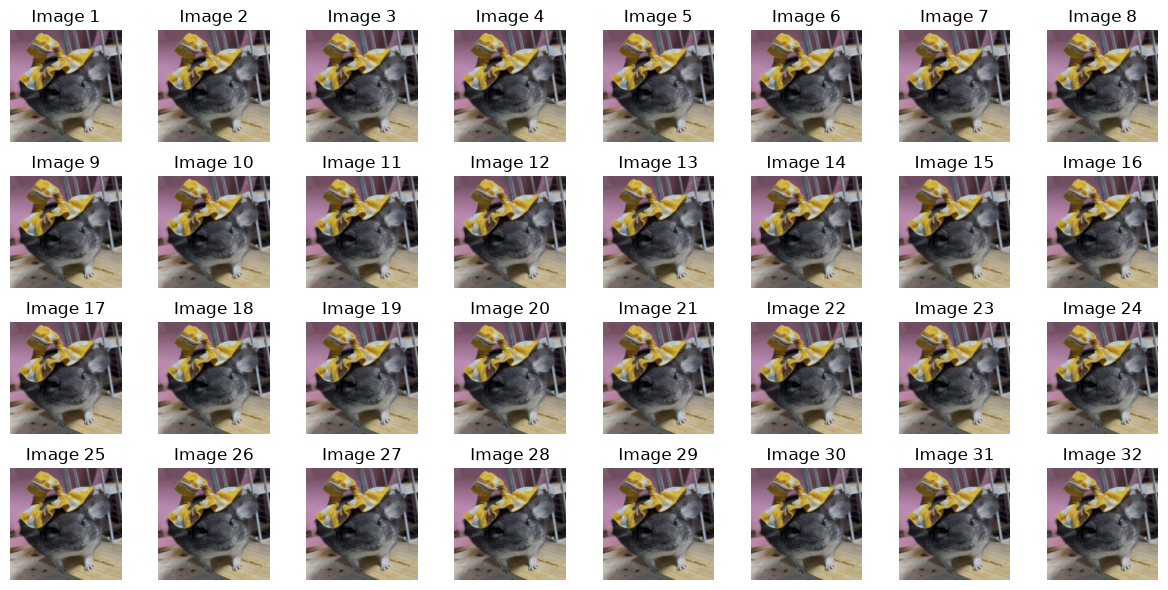

In [ ]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(4, 8, figsize=(12, 6))

for i, ax in enumerate(axes.flat):
    ax.imshow(batch_32[i].permute(1, 2, 0))
    ax.set_title(f"Image {i+1}")
    ax.axis("off")

plt.tight_layout()
plt.show()

# 종합 과제 — 내가 설계한 Tensor

현실의 데이터를 하나 선택합니다.
예: 음식 / 영화 / 운동 / 성적 / 이미지 / 센서 데이터

### 제출 내용
1. 데이터 설명
2. Tensor shape 설계
3. 왜 그 shape인지 설명
4. PyTorch Tensor 구현
5. 결과값 3개 이상 계산
6. 결과를 한 문장으로 해석

### 핵심
코드를 많이 작성하는 것이 아니라 **데이터를 적절한 Tensor 구조로 설계하는 것**이 중요합니다.

# 오늘의 정리

- **Tensor는 데이터를 숫자로 표현하는 PyTorch의 기본 자료구조**
- 이미지·동영상·음성도 **Tensor로 변환하여 처리할 수 있음**
- Tensor의 **shape를 통해 데이터의 구조를 확인할 수 있음**
- Tensor는 **indexing, reshape, 연산**을 통해 원하는 형태로 다룰 수 있음
- **dtype과 device**를 확인하여 데이터의 자료형과 연산 위치를 파악할 수 있음
- Tensor로 표현된 데이터는 **Neural Network의 입력으로 연결됨**

## 에러 시 확인

```python
print(x.shape)
```
> **Tensor를 다룰 때는 값만 보지 말고, 항상 데이터의 구조(shape)를 먼저 확인**
>
> 데이터의 구조를 이해하는 것이 **Tensor를 다루는 첫 번째 단계**